# Unit 10: Uber Marketplace Optimization
## Pareto Frontier Analysis — Driver vs. Rider Satisfaction

**Purpose:** Compare 77 combinations of base ride price and maximum wait-time guarantee. Identify efficient choices, compare business strategies, and recommend a practical balance.

This notebook uses a **synthetic teaching dataset**, not actual Uber operating data. The scores are illustrative and should not be presented as measured customer or driver results.

## 1. Load the synthetic data

Place `satisfaction_data.csv` in the same folder as this notebook before running it.

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from mpl_toolkits.mplot3d import Axes3D  # enables 3D plotting

df = pd.read_csv("satisfaction_data.csv")

print("First 10 rows of data:")
display(df.head(10))
print(f"\nDataset shape: {df.shape}")
print(f"Price range: ${df['price'].min():.2f} to ${df['price'].max():.2f}")
print(f"Wait time range: {df['wait_time_minutes'].min():.0f} to {df['wait_time_minutes'].max():.0f} minutes")

First 10 rows of data:


,price,wait_time_minutes,driver_satisfaction,rider_satisfaction
0,10,3,22,93
1,10,5,24,86
2,10,7,27,80
3,10,9,29,74
4,10,11,31,68
5,10,13,34,61
6,10,15,36,55
7,12,3,28,91
8,12,5,31,85
9,12,7,33,78



Dataset shape: (77, 4)
Price range: $10.00 to $30.00
Wait time range: 3 to 15 minutes


## 2. Validate and explore the data

The expected dataset has 77 rows: 11 prices ($10–$30 in $2 steps) and 7 wait-time guarantees (3–15 minutes in 2-minute steps).

In [17]:
expected_prices = list(range(10, 31, 2))
expected_waits = list(range(3, 16, 2))

assert len(df) == 77, "Expected 77 rows."
assert list(sorted(df["price"].unique())) == expected_prices
assert list(sorted(df["wait_time_minutes"].unique())) == expected_waits
assert df[["price", "wait_time_minutes", "driver_satisfaction", "rider_satisfaction"]].notna().all().all()
assert df[["driver_satisfaction", "rider_satisfaction"]].apply(lambda col: col.between(0, 100).all()).all()

print("Data validation passed.")
print("\n=== DRIVER SATISFACTION ===")
print(df["driver_satisfaction"].describe())
print("\n=== RIDER SATISFACTION ===")
print(df["rider_satisfaction"].describe())

max_driver_idx = df["driver_satisfaction"].idxmax()
max_rider_idx = df["rider_satisfaction"].idxmax()

print("\n=== BEST CASE FOR EACH STAKEHOLDER ===")
print(f"Driver-optimal: Price=${df.loc[max_driver_idx, 'price']:.2f}, "
      f"Wait={df.loc[max_driver_idx, 'wait_time_minutes']:.0f}min → "
      f"Driver sat={df.loc[max_driver_idx, 'driver_satisfaction']:.1f}, "
      f"Rider sat={df.loc[max_driver_idx, 'rider_satisfaction']:.1f}")
print(f"Rider-optimal: Price=${df.loc[max_rider_idx, 'price']:.2f}, "
      f"Wait={df.loc[max_rider_idx, 'wait_time_minutes']:.0f}min → "
      f"Driver sat={df.loc[max_rider_idx, 'driver_satisfaction']:.1f}, "
      f"Rider sat={df.loc[max_rider_idx, 'rider_satisfaction']:.1f}")

Data validation passed.

=== DRIVER SATISFACTION ===
count    77.000000
mean     57.155844
std      17.808237
min      22.000000
25%      42.000000
50%      58.000000
75%      71.000000
max      90.000000
Name: driver_satisfaction, dtype: float64

=== RIDER SATISFACTION ===
count    77.000000
mean     63.129870
std      14.656012
min      32.000000
25%      53.000000
50%      64.000000
75%      74.000000
max      93.000000
Name: rider_satisfaction, dtype: float64

=== BEST CASE FOR EACH STAKEHOLDER ===
Driver-optimal: Price=$30.00, Wait=15min → Driver sat=90.0, Rider sat=32.0
Rider-optimal: Price=$10.00, Wait=3min → Driver sat=22.0, Rider sat=93.0


## 3. Identify the Pareto frontier

A point is efficient if there is no other option with **at least as much driver satisfaction and at least as much rider satisfaction**, and strictly more of one.

In [18]:
def is_pareto_optimal(idx, data):
    current_driver = data.loc[idx, "driver_satisfaction"]
    current_rider = data.loc[idx, "rider_satisfaction"]

    for other_idx in data.index:
        if other_idx == idx:
            continue
        other_driver = data.loc[other_idx, "driver_satisfaction"]
        other_rider = data.loc[other_idx, "rider_satisfaction"]

        if (other_driver >= current_driver and
            other_rider >= current_rider and
            (other_driver > current_driver or other_rider > current_rider)):
            return False
    return True

df["is_pareto_optimal"] = df.index.map(lambda idx: is_pareto_optimal(idx, df))
pareto_df = df[df["is_pareto_optimal"]].copy()
dominated_df = df[~df["is_pareto_optimal"]].copy()

print("=== CALCULATING PARETO FRONTIER ===")
print(f"Total combinations analyzed: {len(df)}")
print(f"Pareto optimal combinations: {len(pareto_df)}")
print(f"Dominated (inefficient) combinations: {len(dominated_df)}")
print(f"Percentage efficient: {100 * len(pareto_df) / len(df):.1f}%")

=== CALCULATING PARETO FRONTIER ===
Total combinations analyzed: 77
Pareto optimal combinations: 17
Dominated (inefficient) combinations: 60
Percentage efficient: 22.1%


## 4. Analyze the efficient frontier

In [19]:
pareto_sorted = pareto_df.sort_values("driver_satisfaction")

print("=== PARETO FRONTIER: EFFICIENT PRICING STRATEGIES ===")
print(pareto_sorted[["price", "wait_time_minutes", "driver_satisfaction", "rider_satisfaction"]].to_string(index=False))
print(f"\nPrice range on Pareto frontier: ${pareto_df['price'].min():.2f} to ${pareto_df['price'].max():.2f}")
print(f"Wait time range on Pareto frontier: {pareto_df['wait_time_minutes'].min():.0f} to {pareto_df['wait_time_minutes'].max():.0f} minutes")

=== PARETO FRONTIER: EFFICIENT PRICING STRATEGIES ===
 price  wait_time_minutes  driver_satisfaction  rider_satisfaction
    10                  3                   22                  93
    12                  3                   28                  91
    14                  3                   34                  89
    16                  3                   40                  87
    18                  3                   46                  85
    20                  3                   51                  82
    22                  3                   56                  80
    24                  3                   62                  78
    26                  3                   67                  75
    28                  3                   71                  73
    30                  3                   76                  70
    30                  5                   78                  64
    30                  7                   81                  57
    30  

## 5. Show examples of dominated strategies

A dominated option is inefficient because another available combination scores at least as high for both groups and higher for at least one.

In [20]:
if len(dominated_df) > 0:
    print("=== EXAMPLES OF DOMINATED STRATEGIES ===")
    for idx, row in dominated_df.head(5).iterrows():
        print(f"DOMINATED: Price=${row['price']:.2f}, Wait={row['wait_time_minutes']:.0f}min "
              f"→ Driver={row['driver_satisfaction']}, Rider={row['rider_satisfaction']}")
        dominators = pareto_df[
            (pareto_df["driver_satisfaction"] >= row["driver_satisfaction"]) &
            (pareto_df["rider_satisfaction"] >= row["rider_satisfaction"]) &
            ((pareto_df["driver_satisfaction"] > row["driver_satisfaction"]) |
             (pareto_df["rider_satisfaction"] > row["rider_satisfaction"]))
        ]
        if not dominators.empty:
            better = dominators.iloc[0]
            print(f"  BETTER:    Price=${better['price']:.2f}, Wait={better['wait_time_minutes']:.0f}min "
                  f"→ Driver={better['driver_satisfaction']}, Rider={better['rider_satisfaction']}\n")

=== EXAMPLES OF DOMINATED STRATEGIES ===
DOMINATED: Price=$10.00, Wait=5min → Driver=24, Rider=86
  BETTER:    Price=$12.00, Wait=3min → Driver=28, Rider=91

DOMINATED: Price=$10.00, Wait=7min → Driver=27, Rider=80
  BETTER:    Price=$12.00, Wait=3min → Driver=28, Rider=91

DOMINATED: Price=$10.00, Wait=9min → Driver=29, Rider=74
  BETTER:    Price=$14.00, Wait=3min → Driver=34, Rider=89

DOMINATED: Price=$10.00, Wait=11min → Driver=31, Rider=68
  BETTER:    Price=$14.00, Wait=3min → Driver=34, Rider=89

DOMINATED: Price=$10.00, Wait=13min → Driver=34, Rider=61
  BETTER:    Price=$14.00, Wait=3min → Driver=34, Rider=89



## 6. Compare three strategies on the frontier

- **Balanced/utilitarian:** maximize the sum of driver and rider satisfaction.
- **Equity:** minimize the absolute gap between driver and rider satisfaction.
- **Rider-priority:** give rider satisfaction 60% weight and driver satisfaction 40%.

In [21]:
pareto_df["total_satisfaction"] = (
    pareto_df["driver_satisfaction"] + pareto_df["rider_satisfaction"]
)
balanced_idx = pareto_df["total_satisfaction"].idxmax()

pareto_df["satisfaction_gap"] = abs(
    pareto_df["driver_satisfaction"] - pareto_df["rider_satisfaction"]
)
equity_idx = pareto_df["satisfaction_gap"].idxmin()

pareto_df["weighted_satisfaction"] = (
    0.4 * pareto_df["driver_satisfaction"] +
    0.6 * pareto_df["rider_satisfaction"]
)
weighted_idx = pareto_df["weighted_satisfaction"].idxmax()

for label, idx in [
    ("BALANCED (maximum total satisfaction)", balanced_idx),
    ("EQUITY (smallest satisfaction gap)", equity_idx),
    ("RIDER-PRIORITY (60% rider / 40% driver)", weighted_idx)
]:
    row = pareto_df.loc[idx]
    print(f"\n{label}")
    print(f"Price: ${row['price']:.2f}; Wait: {row['wait_time_minutes']:.0f} minutes")
    print(f"Driver satisfaction: {row['driver_satisfaction']}")
    print(f"Rider satisfaction: {row['rider_satisfaction']}")
    print(f"Total satisfaction: {row['total_satisfaction']}")


BALANCED (maximum total satisfaction)
Price: $30.00; Wait: 3 minutes
Driver satisfaction: 76
Rider satisfaction: 70
Total satisfaction: 146

EQUITY (smallest satisfaction gap)
Price: $28.00; Wait: 3 minutes
Driver satisfaction: 71
Rider satisfaction: 73
Total satisfaction: 144

RIDER-PRIORITY (60% rider / 40% driver)
Price: $30.00; Wait: 3 minutes
Driver satisfaction: 76
Rider satisfaction: 70
Total satisfaction: 146


## 7. Visualize the results

The three panels show (1) the decision choices, (2) the satisfaction tradeoff and efficient frontier, and (3) a 3D view of price, wait time, and combined satisfaction.

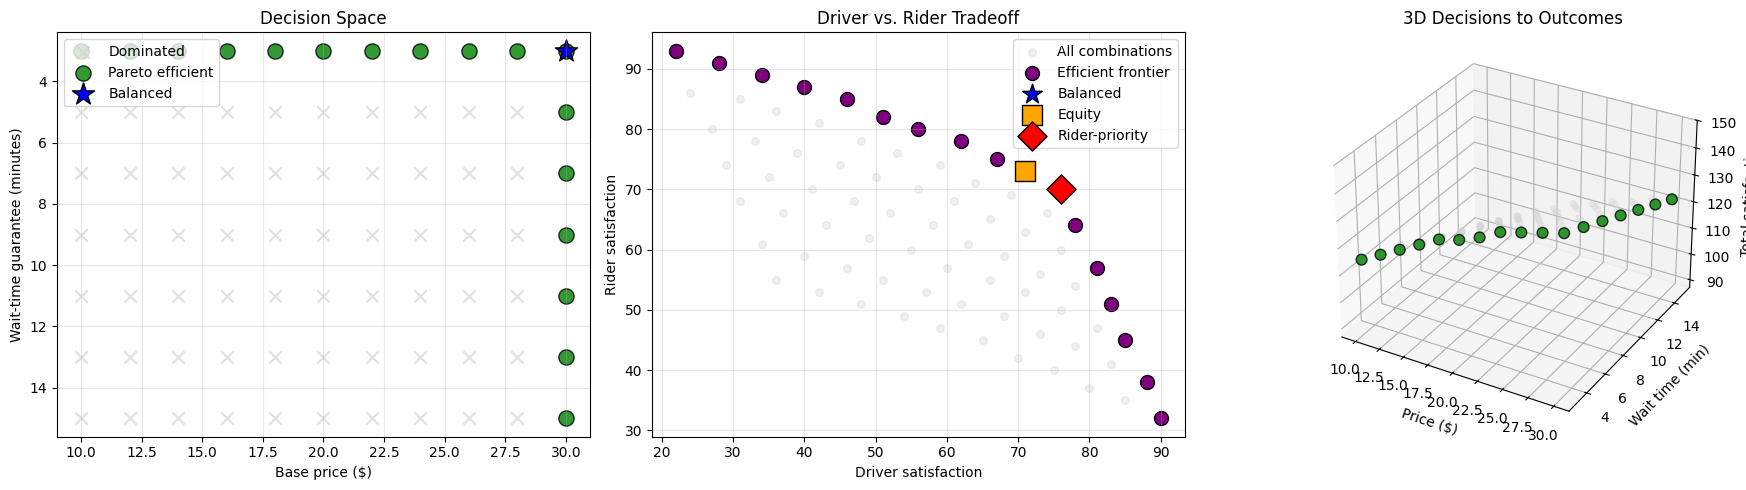

Visualization saved as uber_pareto_analysis.png


In [22]:
fig = plt.figure(figsize=(18, 5))

# Plot 1: Decision space
ax1 = fig.add_subplot(131)
ax1.scatter(dominated_df["price"], dominated_df["wait_time_minutes"],
            s=80, c="lightgray", alpha=0.7, marker="x", label="Dominated")
ax1.scatter(pareto_df["price"], pareto_df["wait_time_minutes"],
            s=120, c="green", alpha=0.8, marker="o", edgecolors="black",
            label="Pareto efficient")
ax1.scatter(pareto_df.loc[balanced_idx, "price"],
            pareto_df.loc[balanced_idx, "wait_time_minutes"],
            s=280, c="blue", marker="*", edgecolors="black", label="Balanced")
ax1.set_xlabel("Base price ($)")
ax1.set_ylabel("Wait-time guarantee (minutes)")
ax1.set_title("Decision Space")
ax1.legend()
ax1.grid(alpha=0.3)
ax1.invert_yaxis()

# Plot 2: Objective space
ax2 = fig.add_subplot(132)
ax2.scatter(df["driver_satisfaction"], df["rider_satisfaction"],
            s=30, c="lightgray", alpha=0.35, label="All combinations")
ax2.scatter(pareto_df["driver_satisfaction"], pareto_df["rider_satisfaction"],
            s=100, c="purple", edgecolors="black", label="Efficient frontier")
strategies = [
    (balanced_idx, "blue", "*", "Balanced"),
    (equity_idx, "orange", "s", "Equity"),
    (weighted_idx, "red", "D", "Rider-priority")
]
for idx, color, marker, label in strategies:
    ax2.scatter(pareto_df.loc[idx, "driver_satisfaction"],
                pareto_df.loc[idx, "rider_satisfaction"],
                s=220, c=color, marker=marker, edgecolors="black", label=label, zorder=5)
ax2.set_xlabel("Driver satisfaction")
ax2.set_ylabel("Rider satisfaction")
ax2.set_title("Driver vs. Rider Tradeoff")
ax2.legend()
ax2.grid(alpha=0.3)

# Plot 3: 3D decision/outcome view
ax3 = fig.add_subplot(133, projection="3d")
df_total = df["driver_satisfaction"] + df["rider_satisfaction"]
pareto_total = pareto_df["driver_satisfaction"] + pareto_df["rider_satisfaction"]
ax3.scatter(df["price"], df["wait_time_minutes"], df_total,
            c="lightgray", alpha=0.3, s=20)
ax3.scatter(pareto_df["price"], pareto_df["wait_time_minutes"], pareto_total,
            c="green", alpha=0.8, s=60, edgecolors="black")
ax3.set_xlabel("Price ($)")
ax3.set_ylabel("Wait time (min)")
ax3.set_zlabel("Total satisfaction")
ax3.set_title("3D Decisions to Outcomes")

plt.tight_layout()
plt.savefig("uber_pareto_analysis.png", dpi=300, bbox_inches="tight")
plt.show()
print("Visualization saved as uber_pareto_analysis.png")

## 8. Executive comparison table

In [23]:
strategy_points = [
    ("Driver-Optimal", max_driver_idx, df),
    ("Balanced", balanced_idx, pareto_df),
    ("Equity", equity_idx, pareto_df),
    ("Rider-Priority", weighted_idx, pareto_df),
    ("Rider-Optimal", max_rider_idx, df)
]

summary_rows = []
for strategy_name, idx, source in strategy_points:
    row = source.loc[idx]
    summary_rows.append({
        "Strategy": strategy_name,
        "Price": f"${row['price']:.2f}",
        "Wait Time": f"{row['wait_time_minutes']:.0f} min",
        "Driver Sat": row["driver_satisfaction"],
        "Rider Sat": row["rider_satisfaction"],
        "Total Sat": row["driver_satisfaction"] + row["rider_satisfaction"]
    })

comparison_df = pd.DataFrame(summary_rows)
display(comparison_df)
print(f"{len(dominated_df)} of {len(df)} combinations are dominated.")
print(f"{len(pareto_df)} combinations are on the efficient frontier.")

,Strategy,Price,Wait Time,Driver Sat,Rider Sat,Total Sat
0,Driver-Optimal,$30.00,15 min,90,32,122
1,Balanced,$30.00,3 min,76,70,146
2,Equity,$28.00,3 min,71,73,144
3,Rider-Priority,$30.00,3 min,76,70,146
4,Rider-Optimal,$10.00,3 min,22,93,115


60 of 77 combinations are dominated.
17 combinations are on the efficient frontier.


## 9. Findings and executive recommendation

Use the printed strategy table and plots to support your final recommendation. A reasonable starting recommendation is the **balanced strategy**, because it maximizes combined satisfaction in this model rather than favoring only one group. Confirm the exact price, wait-time guarantee, and scores from your notebook output before recording.

This is a simplified synthetic model. It does not include real Uber data, operating costs, profit margins, local supply and demand, time of day, rider segments, driver retention, or competitor pricing. A real decision should pilot-test the selected option in one market, survey both groups, and monitor driver retention, rider churn, and trips per driver per hour.

## 10. Suggested executive presentation outline (maximum 5 minutes)

1. **Business problem (about 60 seconds):** Uber chooses both base price and wait-time guarantee. Higher prices can help drivers but upset riders; shorter waits help riders but can reduce driver utilization.
2. **Efficient frontier (about 90 seconds):** Explain that gray points are dominated and the frontier contains options where improving one group's satisfaction means sacrificing some of the other's. Show the middle plot.
3. **Recommendation (about 90 seconds):** State your selected strategy and read its exact price, wait time, and two satisfaction scores from the notebook output. Explain why the tradeoff makes business sense.
4. **Implementation and limitations (about 60 seconds):** Recommend a pilot, surveys, and monitoring driver retention, rider churn, and trips per driver per hour. Acknowledge that the dataset is synthetic and excludes real-world market factors.